In [17]:
import re, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from IPython.display import display

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report)
nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)
nltk.download("omw-1.4", quiet=True)

True

In [4]:
p = r"C:\Users\katta\OneDrive\Documents\IMDB Dataset.csv\IMDB Dataset.csv"
print(os.path.isfile(p), round(os.path.getsize(p) / 1e6, 1), "MB")

df = pd.read_csv(p)
print(df.shape)
df.head()

True 66.2 MB
(50000, 2)


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


sentiment
positive    25000
negative    25000
Name: count, dtype: int64
Missing values: 0
Duplicate reviews: 418


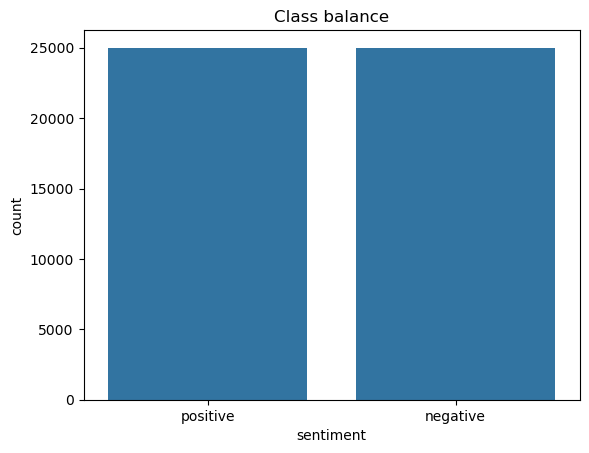

In [5]:
print(df["sentiment"].value_counts())
print("Missing values:", df.isnull().sum().sum())
print("Duplicate reviews:", df.duplicated().sum())

sns.countplot(x="sentiment", data=df)
plt.title("Class balance")
plt.show()

In [6]:
df = df.drop_duplicates().reset_index(drop=True)

lemmatizer = WordNetLemmatizer()
negations = {"not", "no", "nor", "never", "don", "doesn", "didn", "isn", "wasn",
             "aren", "weren", "won", "wouldn", "couldn", "shouldn", "hadn", "hasn", "haven"}
stop_words = set(stopwords.words("english")) - negations

def clean_text(text):
    text = text.lower()
    text = re.sub(r"<.*?>", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    tokens = [lemmatizer.lemmatize(w) for w in text.split() if w not in stop_words]
    return " ".join(tokens)

df["clean_review"] = df["review"].apply(clean_text)
df["label"] = df["sentiment"].map({"negative": 0, "positive": 1})

print(df.loc[0, "review"][:300])
print("---")
print(df.loc[0, "clean_review"][:300])

One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Tru
---
one reviewer mentioned watching oz episode hooked right exactly happened first thing struck oz brutality unflinching scene violence set right word go trust not show faint hearted timid show pull no punch regard drug sex violence hardcore classic use word called oz nickname given oswald maximum secur


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    df["clean_review"], df["label"],
    test_size=0.2, random_state=42, stratify=df["label"]
)

tfidf = TfidfVectorizer(max_features=30000, ngram_range=(1, 2), min_df=3)
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Train:", X_train.shape[0], "| Test:", X_test.shape[0])
print("Feature matrix:", X_train_tfidf.shape)

Train: 39665 | Test: 9917
Feature matrix: (39665, 30000)


In [8]:
models = {
    "Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(max_iter=1000, C=1.0),
    "Linear SVM": LinearSVC(C=0.5),
}

results = []
predictions = {}

for name, model in models.items():
    model.fit(X_train_tfidf, y_train)
    y_pred = model.predict(X_test_tfidf)
    predictions[name] = y_pred
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
    })

results_df = pd.DataFrame(results).set_index("Model").round(4)
results_df

,Accuracy,Precision,Recall,F1
Model,,,,
Naive Bayes,0.8828,0.8763,0.8925,0.8843
Logistic Regression,0.9016,0.8922,0.9144,0.9032
Linear SVM,0.9059,0.9009,0.9130,0.9069


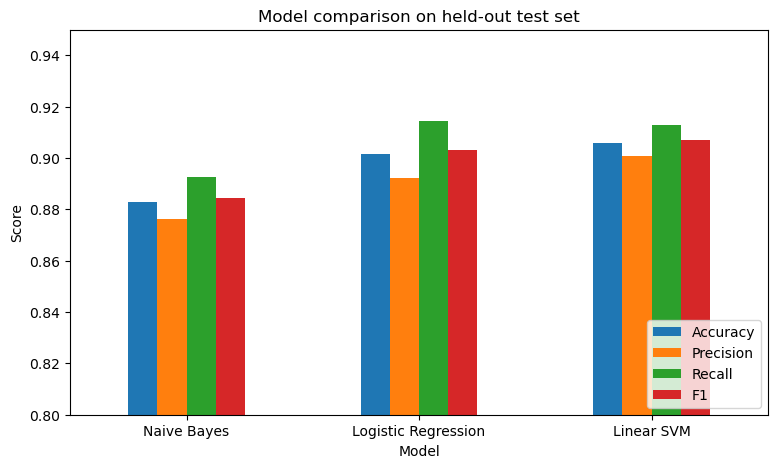

In [9]:
results_df.plot(kind="bar", figsize=(9, 5))
plt.ylim(0.8, 0.95)
plt.title("Model comparison on held-out test set")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.show()

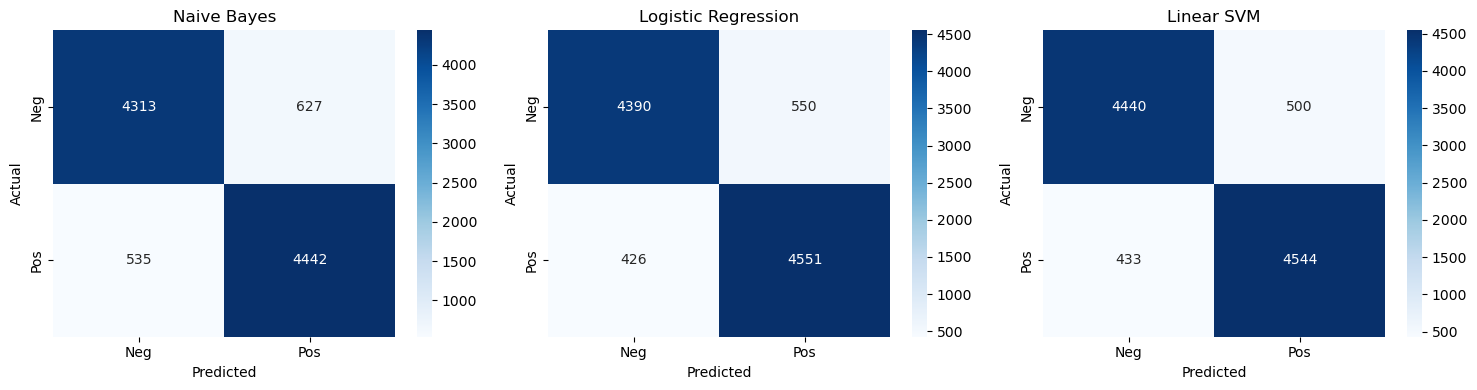

Best model: Linear SVM
              precision    recall  f1-score   support

    negative       0.91      0.90      0.90      4940
    positive       0.90      0.91      0.91      4977

    accuracy                           0.91      9917
   macro avg       0.91      0.91      0.91      9917
weighted avg       0.91      0.91      0.91      9917



In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=["Neg", "Pos"], yticklabels=["Neg", "Pos"])
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

best_name = results_df["F1"].idxmax()
print("Best model:", best_name)
print(classification_report(y_test, predictions[best_name], target_names=["negative", "positive"]))

In [11]:
for name, model in models.items():
    scores = cross_val_score(model, X_train_tfidf, y_train, cv=5, scoring="accuracy")
    print(f"{name:20s} mean={scores.mean():.4f}  std={scores.std():.4f}")

Naive Bayes          mean=0.8786  std=0.0020
Logistic Regression  mean=0.8987  std=0.0020
Linear SVM           mean=0.9029  std=0.0013


In [12]:
pipe = Pipeline([
    ("tfidf", TfidfVectorizer(min_df=3)),
    ("clf", LogisticRegression(max_iter=1000)),
])

param_grid = {
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "tfidf__max_features": [20000, 40000],
    "clf__C": [0.5, 1, 5, 10],
}

grid = GridSearchCV(pipe, param_grid, cv=3, scoring="accuracy", n_jobs=-1, verbose=1)
grid.fit(X_train, y_train)

print("Best params:", grid.best_params_)
print("Best CV accuracy:", round(grid.best_score_, 4))
print("Test accuracy:", round(accuracy_score(y_test, grid.predict(X_test)), 4))

Fitting 3 folds for each of 16 candidates, totalling 48 fits
Best params: {'clf__C': 5, 'tfidf__max_features': 40000, 'tfidf__ngram_range': (1, 2)}
Best CV accuracy: 0.9026
Test accuracy: 0.9064


In [13]:
best_model = grid.best_estimator_

check = pd.DataFrame({
    "review": df.loc[X_test.index, "review"].str[:120],
    "actual": y_test.map({0: "negative", 1: "positive"}),
    "predicted": pd.Series(best_model.predict(X_test), index=X_test.index).map({0: "negative", 1: "positive"}),
})
check["correct"] = check["actual"] == check["predicted"]

print("Sample of 10 predictions:")
display(check.sample(10, random_state=1))

print("\nMisclassified reviews:")
display(check[~check["correct"]].head(10))

Sample of 10 predictions:


,review,actual,predicted,correct
2009,"Stuck in a hotel in Kuwait, I happily switched...",positive,positive,True
27280,"One of the major aspects of ""Malenkaya Vera"" (...",positive,positive,True
32406,"As others have mentioned, all the women that g...",positive,positive,True
30408,Imagine the most cliche ridden b-movie horror ...,negative,negative,True
9638,Critters 4 ranks as one of the greatest films ...,positive,positive,True
47865,"Lois Weber, self proclaimed missionary via the...",negative,negative,True
39495,I was pleasantly surprised to find a very enjo...,positive,positive,True
18847,This film is definitely a product of its times...,negative,negative,True
8382,"Okay, now, I know there are millions of Americ...",negative,negative,True
12736,Final Score (an average of various classic cin...,negative,negative,True



Misclassified reviews:


,review,actual,predicted,correct
45455,"This isn't exactly a great film, but I admire ...",positive,negative,False
34520,Despite being a huge fan of Fred Astaire and G...,negative,positive,False
32702,"Writer & director Robert Downey, Sr., a pionee...",negative,positive,False
27110,"Well, well....Roeg touched a bit of a nerve th...",positive,negative,False
14394,"I'm not here to tell you ""Armored"" is Kubricki...",positive,negative,False
12423,"this movie probably had a $750 budget, and sti...",positive,negative,False
29296,Financially strapped Paramount pulled out all ...,positive,negative,False
8717,"Richard Dix is a big, not very nice industrial...",negative,positive,False
39870,"""Black Vengeance"" is an alternate title for ""Y...",negative,positive,False
32198,For those who like depressing films with sleaz...,negative,positive,False


In [14]:
vec = best_model.named_steps["tfidf"]
clf = best_model.named_steps["clf"]
words = np.array(vec.get_feature_names_out())
order = np.argsort(clf.coef_[0])

print("Most NEGATIVE words:", list(words[order[:15]]))
print("Most POSITIVE words:", list(words[order[-15:]]))

Most NEGATIVE words: ['worst', 'awful', 'bad', 'waste', 'boring', 'poor', 'fails', 'horrible', 'terrible', 'disappointment', 'disappointing', 'poorly', 'dull', 'forgettable', 'annoying']
Most POSITIVE words: ['superb', 'loved', 'favorite', 'one best', 'subtle', 'enjoyable', 'brilliant', 'best', 'hilarious', 'wonderful', 'must see', 'amazing', 'perfect', 'excellent', 'great']


In [15]:
def predict_sentiment(review, model=best_model):
    cleaned = clean_text(review)
    prob_pos = model.predict_proba([cleaned])[0][1]
    label = "Positive" if prob_pos >= 0.5 else "Negative"
    confidence = prob_pos if label == "Positive" else 1 - prob_pos
    return label, round(confidence * 100, 1)

samples = [
    "An absolute masterpiece. The acting was brilliant and the story kept me hooked.",
    "Terrible movie. Boring plot, awful acting, and a complete waste of time.",
    "The movie was not good at all.",
    "I expected much more, but the ending was decent.",
]

for s in samples:
    label, conf = predict_sentiment(s)
    print(f"{label:9s} ({conf}%)  ->  {s}")

Positive  (95.8%)  ->  An absolute masterpiece. The acting was brilliant and the story kept me hooked.
Negative  (100.0%)  ->  Terrible movie. Boring plot, awful acting, and a complete waste of time.
Negative  (99.1%)  ->  The movie was not good at all.
Negative  (66.0%)  ->  I expected much more, but the ending was decent.


In [16]:
joblib.dump(best_model, "sentiment_model.joblib")

['sentiment_model.joblib']